In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# настройки отображения
pd.set_option('display.max_columns', None)
plt.rcParams['figure.figsize'] = (10, 5)
sns.set_style('whitegrid')  

# загружаем данные
df = pd.read_csv('cookie_cats.csv')

print("Размер таблицы:", df.shape)
df.head()

Размер таблицы: (90189, 5)


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


In [2]:
# 1. Типы данных и пропуски
print("=== Инфо о данных ===")
df.info()

# 2. Пропущенные значения по столбцам
print("\n=== Пропуски ===")
print(df.isnull().sum())

# 3. Дубликаты по userid (один игрок не должен встречаться дважды)
print("\n=== Дубликаты userid ===")
print("Повторяющихся userid:", df['userid'].duplicated().sum())

# 4. Какие вообще значения в столбце version
print("\n=== Значения version ===")
print(df['version'].value_counts())

=== Инфо о данных ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   userid          90189 non-null  int64 
 1   version         90189 non-null  object
 2   sum_gamerounds  90189 non-null  int64 
 3   retention_1     90189 non-null  bool  
 4   retention_7     90189 non-null  bool  
dtypes: bool(2), int64(2), object(1)
memory usage: 2.2+ MB

=== Пропуски ===
userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64

=== Дубликаты userid ===
Повторяющихся userid: 0

=== Значения version ===
version
gate_40    45489
gate_30    44700
Name: count, dtype: int64


In [3]:
from scipy.stats import chisquare

# фактические размеры групп
n_gate30 = (df['version'] == 'gate_30').sum()
n_gate40 = (df['version'] == 'gate_40').sum()
n_total = n_gate30 + n_gate40

observed = [n_gate30, n_gate40]          # что получили по факту
expected = [n_total / 2, n_total / 2]     # что ждали при честном 50/50

print(f"Фактически:  gate_30 = {n_gate30},  gate_40 = {n_gate40}")
print(f"Ожидалось:   по {n_total/2:.1f} в каждой группе")
print(f"Разница:     {abs(n_gate30 - n_gate40)} игроков")

# доля тестовой группы
print(f"Доля gate_40: {n_gate40 / n_total:.4f}  (ждём около 0.5)")

# тест хи-квадрат
chi2_stat, p_value = chisquare(f_obs=observed, f_exp=expected)

print(f"\nChi2-статистика: {chi2_stat:.4f}")
print(f"p-value:         {p_value:.4f}")

# вывод по порогу 0.001
if p_value < 0.001:
    print("\n❌ SRM ОБНАРУЖЕН: группы поделены некорректно, результатам доверять нельзя.")
else:
    print("\n✅ SRM НЕ обнаружен: разница в размерах групп — обычная случайность, всё ок.")

Фактически:  gate_30 = 44700,  gate_40 = 45489
Ожидалось:   по 45094.5 в каждой группе
Разница:     789 игроков
Доля gate_40: 0.5044  (ждём около 0.5)

Chi2-статистика: 6.9024
p-value:         0.0086

✅ SRM НЕ обнаружен: разница в размерах групп — обычная случайность, всё ок.


## Шаг 1. Проверка корректности эксперимента (SRM)

**Вопрос:** корректно ли игроки поделились на группы 50/50?

**Метод:** тест хи-квадрат на соответствие ожидаемому делению 50/50, строгий порог значимости 0.001 (стандарт для SRM).

**Результат:**
- Фактическое деление: gate_30 = 44 700, gate_40 = 45 489 (доля тестовой группы 50.44%)
- p-value = 0.0086 > 0.001 → **SRM не обнаружен**

**Вывод:** рандомизация корректна, дальнейшим сравнениям можно доверять. Небольшой перекос (0.44 п.п.) статистически заметен по порогу 0.05 из-за большого объёма выборки (n=90k), но практически незначим.

In [4]:
# Считаем удержание по группам
retention_summary = df.groupby('version').agg(
    n_players=('userid', 'count'),
    retention_1=('retention_1', 'mean'),
    retention_7=('retention_7', 'mean')
)

print("=== Удержание по группам ===")
print(retention_summary)

# Отдельно посчитаем абсолютные числа вернувшихся (пригодится для тестов)
print("\n=== Абсолютные числа ===")
for group in ['gate_30', 'gate_40']:
    sub = df[df['version'] == group]
    print(f"\n{group}:")
    print(f"  всего игроков:      {len(sub)}")
    print(f"  вернулись на 1 день: {sub['retention_1'].sum()}  ({sub['retention_1'].mean()*100:.2f}%)")
    print(f"  вернулись на 7 день: {sub['retention_7'].sum()}  ({sub['retention_7'].mean()*100:.2f}%)")

=== Удержание по группам ===
         n_players  retention_1  retention_7
version                                     
gate_30      44700     0.448188     0.190201
gate_40      45489     0.442283     0.182000

=== Абсолютные числа ===

gate_30:
  всего игроков:      44700
  вернулись на 1 день: 20034  (44.82%)
  вернулись на 7 день: 8502  (19.02%)

gate_40:
  всего игроков:      45489
  вернулись на 1 день: 20119  (44.23%)
  вернулись на 7 день: 8279  (18.20%)


In [5]:
from statsmodels.stats.proportion import proportion_confint

print("=== 95% доверительные интервалы удержания по группам ===\n")

for metric in ['retention_1', 'retention_7']:
    print(f"--- {metric} ---")
    for group in ['gate_30', 'gate_40']:
        sub = df[df['version'] == group]
        count = sub[metric].sum()      # вернувшихся
        nobs = len(sub)                # всего в группе
        p = count / nobs               # доля
        # интервал Уилсона (точнее обычного для долей)
        low, high = proportion_confint(count, nobs, alpha=0.05, method='wilson')
        print(f"  {group}: {p*100:.2f}%   ДИ [{low*100:.2f}%, {high*100:.2f}%]")
    print()

=== 95% доверительные интервалы удержания по группам ===

--- retention_1 ---
  gate_30: 44.82%   ДИ [44.36%, 45.28%]
  gate_40: 44.23%   ДИ [43.77%, 44.69%]

--- retention_7 ---
  gate_30: 19.02%   ДИ [18.66%, 19.39%]
  gate_40: 18.20%   ДИ [17.85%, 18.56%]



In [6]:
from statsmodels.stats.proportion import confint_proportions_2indep

print("=== 95% ДИ для РАЗНИЦЫ удержания (gate_40 − gate_30) ===\n")

for metric in ['retention_1', 'retention_7']:
    # gate_40 — тест, gate_30 — контроль
    g40 = df[df['version'] == 'gate_40'][metric]
    g30 = df[df['version'] == 'gate_30'][metric]

    count40, n40 = g40.sum(), len(g40)
    count30, n30 = g30.sum(), len(g30)

    # разница долей (тест − контроль)
    diff = count40/n40 - count30/n30

    # ДИ для разницы двух независимых пропорций
    low, high = confint_proportions_2indep(
        count40, n40, count30, n30,
        method='wald', compare='diff', alpha=0.05
    )

    print(f"--- {metric} ---")
    print(f"  Разница (gate_40 − gate_30): {diff*100:+.2f} п.п.")
    print(f"  95% ДИ разницы: [{low*100:+.2f} п.п., {high*100:+.2f} п.п.]")
    if low <= 0 <= high:
        print(f"  → интервал СОДЕРЖИТ 0 → разница НЕ значима\n")
    else:
        print(f"  → интервал НЕ содержит 0 → разница ЗНАЧИМА\n")

=== 95% ДИ для РАЗНИЦЫ удержания (gate_40 − gate_30) ===

--- retention_1 ---
  Разница (gate_40 − gate_30): -0.59 п.п.
  95% ДИ разницы: [-1.24 п.п., +0.06 п.п.]
  → интервал СОДЕРЖИТ 0 → разница НЕ значима

--- retention_7 ---
  Разница (gate_40 − gate_30): -0.82 п.п.
  95% ДИ разницы: [-1.33 п.п., -0.31 п.п.]
  → интервал НЕ содержит 0 → разница ЗНАЧИМА



In [7]:
from statsmodels.stats.proportion import proportions_ztest

print("=== Z-тест пропорций для удержания (gate_40 vs gate_30) ===\n")

for metric in ['retention_1', 'retention_7']:
    g40 = df[df['version'] == 'gate_40'][metric]
    g30 = df[df['version'] == 'gate_30'][metric]

    # count = число вернувшихся, nobs = размер группы
    counts = [g40.sum(), g30.sum()]
    nobs = [len(g40), len(g30)]

    z_stat, p_value = proportions_ztest(count=counts, nobs=nobs)

    print(f"--- {metric} ---")
    print(f"  gate_40: {g40.mean()*100:.2f}%   gate_30: {g30.mean()*100:.2f}%")
    print(f"  z-статистика: {z_stat:.4f}")
    print(f"  p-value:      {p_value:.4f}")
    if p_value < 0.05:
        print(f"  → p < 0.05 → разница ЗНАЧИМА\n")
    else:
        print(f"  → p ≥ 0.05 → разница НЕ значима\n")

=== Z-тест пропорций для удержания (gate_40 vs gate_30) ===

--- retention_1 ---
  gate_40: 44.23%   gate_30: 44.82%
  z-статистика: -1.7841
  p-value:      0.0744
  → p ≥ 0.05 → разница НЕ значима

--- retention_7 ---
  gate_40: 18.20%   gate_30: 19.02%
  z-статистика: -3.1644
  p-value:      0.0016
  → p < 0.05 → разница ЗНАЧИМА



In [8]:
import numpy as np

np.random.seed(42)  # для воспроизводимости результата
n_iterations = 10000

print("=== Бутстрап для разницы удержания (gate_40 − gate_30) ===\n")

for metric in ['retention_1', 'retention_7']:
    # массивы 0/1 для каждой группы
    g40 = df[df['version'] == 'gate_40'][metric].values.astype(int)
    g30 = df[df['version'] == 'gate_30'][metric].values.astype(int)

    boot_diffs = np.empty(n_iterations)

    for i in range(n_iterations):
        # пересобираем каждую группу с возвращением
        sample40 = np.random.choice(g40, size=len(g40), replace=True)
        sample30 = np.random.choice(g30, size=len(g30), replace=True)
        # разница удержаний на этой итерации
        boot_diffs[i] = sample40.mean() - sample30.mean()

    # 95% ДИ = 2.5-й и 97.5-й процентили распределения
    ci_low, ci_high = np.percentile(boot_diffs, [2.5, 97.5])
    observed_diff = g40.mean() - g30.mean()

    print(f"--- {metric} ---")
    print(f"  Наблюдаемая разница: {observed_diff*100:+.2f} п.п.")
    print(f"  Бутстрап 95% ДИ: [{ci_low*100:+.2f} п.п., {ci_high*100:+.2f} п.п.]")
    if ci_low <= 0 <= ci_high:
        print(f"  → интервал СОДЕРЖИТ 0 → разница НЕ значима\n")
    else:
        print(f"  → интервал НЕ содержит 0 → разница ЗНАЧИМА\n")

=== Бутстрап для разницы удержания (gate_40 − gate_30) ===

--- retention_1 ---
  Наблюдаемая разница: -0.59 п.п.
  Бутстрап 95% ДИ: [-1.24 п.п., +0.05 п.п.]
  → интервал СОДЕРЖИТ 0 → разница НЕ значима

--- retention_7 ---
  Наблюдаемая разница: -0.82 п.п.
  Бутстрап 95% ДИ: [-1.33 п.п., -0.31 п.п.]
  → интервал НЕ содержит 0 → разница ЗНАЧИМА



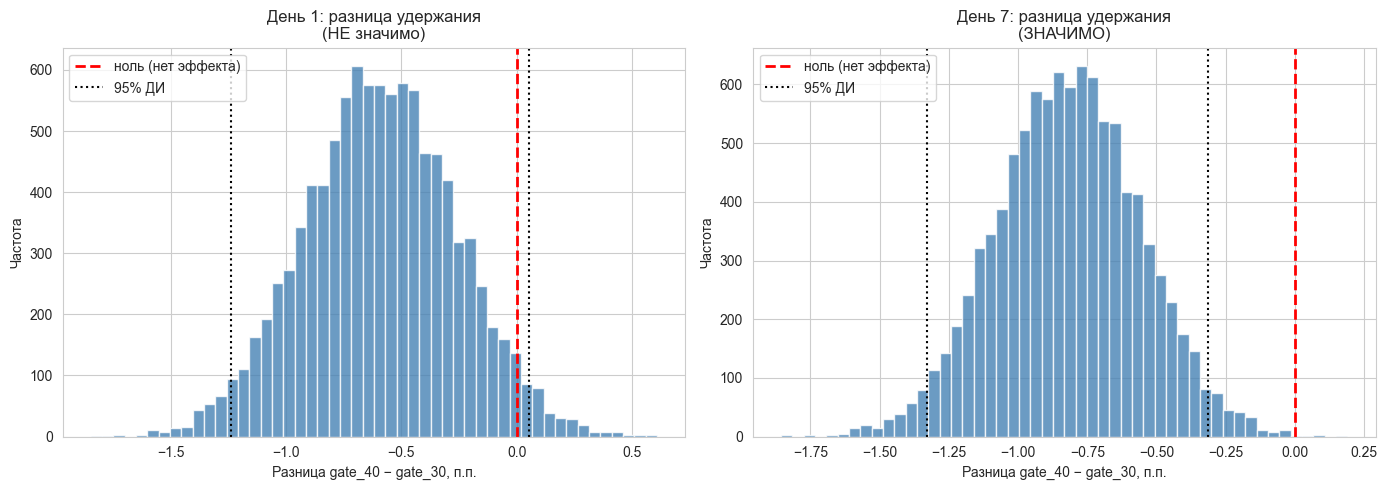

In [9]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
n_iterations = 10000

# считаем и сохраняем распределения для обеих метрик
boot_results = {}
for metric in ['retention_1', 'retention_7']:
    g40 = df[df['version'] == 'gate_40'][metric].values.astype(int)
    g30 = df[df['version'] == 'gate_30'][metric].values.astype(int)
    diffs = np.empty(n_iterations)
    for i in range(n_iterations):
        s40 = np.random.choice(g40, size=len(g40), replace=True)
        s30 = np.random.choice(g30, size=len(g30), replace=True)
        diffs[i] = (s40.mean() - s30.mean()) * 100  # в процентных пунктах
    boot_results[metric] = diffs

# рисуем две гистограммы рядом
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric in zip(axes, ['retention_1', 'retention_7']):
    diffs = boot_results[metric]
    ci_low, ci_high = np.percentile(diffs, [2.5, 97.5])

    ax.hist(diffs, bins=50, color='steelblue', edgecolor='white', alpha=0.8)
    ax.axvline(0, color='red', linestyle='--', linewidth=2, label='ноль (нет эффекта)')
    ax.axvline(ci_low, color='black', linestyle=':', linewidth=1.5, label='95% ДИ')
    ax.axvline(ci_high, color='black', linestyle=':', linewidth=1.5)

    title = 'День 1' if metric == 'retention_1' else 'День 7'
    significance = 'НЕ значимо' if ci_low <= 0 <= ci_high else 'ЗНАЧИМО'
    ax.set_title(f'{title}: разница удержания\n({significance})', fontsize=12)
    ax.set_xlabel('Разница gate_40 − gate_30, п.п.')
    ax.set_ylabel('Частота')
    ax.legend()

plt.tight_layout()
plt.show()

## Шаг 2. Удержание: сравнение групп

**Вопрос:** влияет ли перенос ворот (30 → 40) на удержание игроков?

**Методы:** три независимых подхода для устойчивости вывода — доверительные интервалы (Уилсон/Вальд), z-тест пропорций, бутстрап (10 000 итераций).

**Результаты:**

| Метрика | gate_30 | gate_40 | Разница | p-value (z-тест) | Вывод |
|---|---|---|---|---|---|
| Удержание D1 | 44.82% | 44.23% | −0.59 п.п. | 0.074 | не значимо |
| Удержание D7 | 19.02% | 18.20% | −0.82 п.п. | 0.0016 | **значимо** |

Все три метода дали одинаковый вердикт по обеим метрикам (ДИ и бутстрап совпали до сотых).

**Вывод:** перенос ворот на 40-й уровень **не улучшил** удержание, а на 7-й день **значимо ухудшил** его. На 1-й день видна та же негативная тенденция, но она не достигает значимости. Эффект накапливается со временем — это ключевой сигнал против выката изменения.

In [10]:
print("=== Описательная статистика: sum_gamerounds ===\n")

# общая картина
print(df['sum_gamerounds'].describe())

print("\n=== Ключевые процентили ===")
for q in [0.5, 0.9, 0.95, 0.99, 0.999, 1.0]:
    val = df['sum_gamerounds'].quantile(q)
    print(f"  {q*100:>5.1f}-й процентиль: {val:.0f} раундов")

print("\n=== Среднее vs медиана ===")
print(f"  Среднее:  {df['sum_gamerounds'].mean():.1f} раундов")
print(f"  Медиана:  {df['sum_gamerounds'].median():.0f} раундов")

print("\n=== Максимум (тот самый выброс) ===")
print(f"  Максимум: {df['sum_gamerounds'].max()} раундов")
print(f"  Сколько игроков сыграли 0 раундов: {(df['sum_gamerounds'] == 0).sum()}")

=== Описательная статистика: sum_gamerounds ===

count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64

=== Ключевые процентили ===
   50.0-й процентиль: 16 раундов
   90.0-й процентиль: 134 раундов
   95.0-й процентиль: 221 раундов
   99.0-й процентиль: 493 раундов
   99.9-й процентиль: 1074 раундов
  100.0-й процентиль: 49854 раундов

=== Среднее vs медиана ===
  Среднее:  51.9 раундов
  Медиана:  16 раундов

=== Максимум (тот самый выброс) ===
  Максимум: 49854 раундов
  Сколько игроков сыграли 0 раундов: 3994


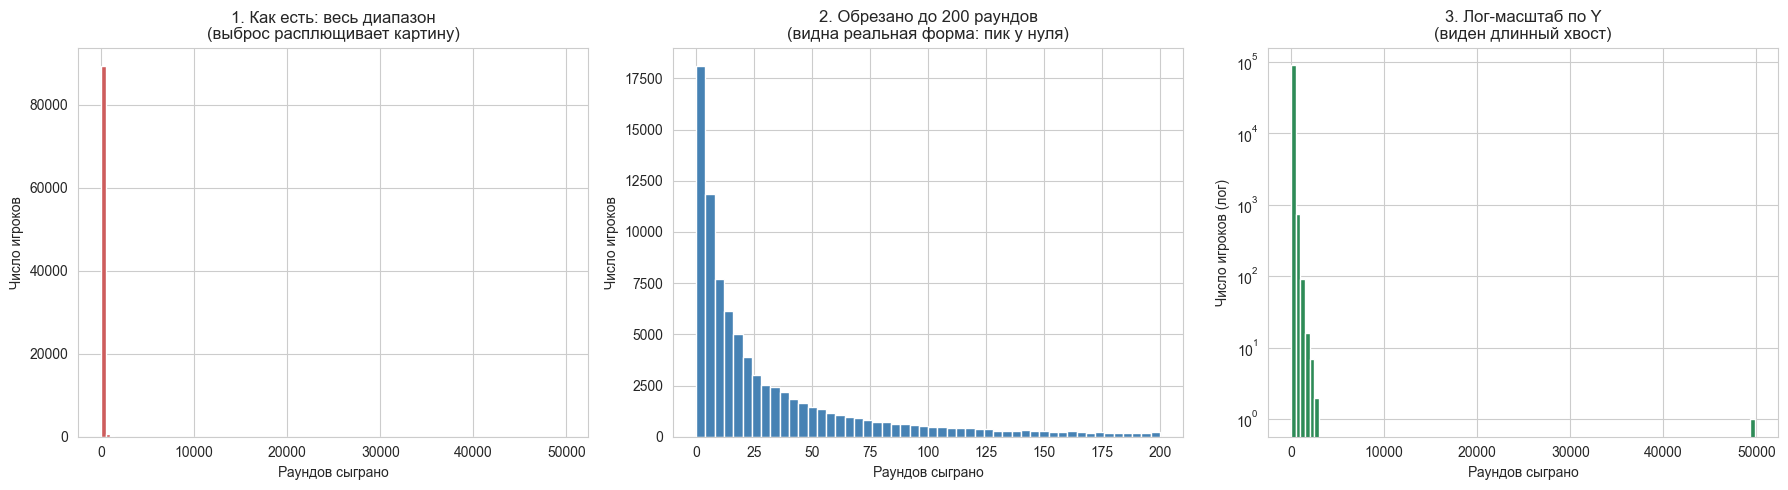

In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Как есть — весь диапазон (хвост всё убивает)
axes[0].hist(df['sum_gamerounds'], bins=100, color='indianred', edgecolor='white')
axes[0].set_title('1. Как есть: весь диапазон\n(выброс расплющивает картину)')
axes[0].set_xlabel('Раундов сыграно')
axes[0].set_ylabel('Число игроков')

# 2. Обрезаем до 200 раундов — видим основную массу
subset = df[df['sum_gamerounds'] <= 200]['sum_gamerounds']
axes[1].hist(subset, bins=50, color='steelblue', edgecolor='white')
axes[1].set_title('2. Обрезано до 200 раундов\n(видна реальная форма: пик у нуля)')
axes[1].set_xlabel('Раундов сыграно')
axes[1].set_ylabel('Число игроков')

# 3. Лог-масштаб по оси Y — виден и хвост, и основная масса
axes[2].hist(df['sum_gamerounds'], bins=100, color='seagreen', edgecolor='white')
axes[2].set_yscale('log')
axes[2].set_title('3. Лог-масштаб по Y\n(виден длинный хвост)')
axes[2].set_xlabel('Раундов сыграно')
axes[2].set_ylabel('Число игроков (лог)')

plt.tight_layout()
plt.show()

In [12]:
print("=== Раунды по группам ===\n")

summary = df.groupby('version')['sum_gamerounds'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)
print(summary)

print("\n=== Медианы и средние крупным планом ===")
for group in ['gate_30', 'gate_40']:
    sub = df[df['version'] == group]['sum_gamerounds']
    print(f"\n{group}:")
    print(f"  среднее: {sub.mean():.2f}")
    print(f"  медиана: {sub.median():.1f}")
    print(f"  90-й процентиль: {sub.quantile(0.9):.0f}")

=== Раунды по группам ===

         count       mean  median         std  min    max
version                                                  
gate_30  44700  52.456264    17.0  256.716423    0  49854
gate_40  45489  51.298776    16.0  103.294416    0   2640

=== Медианы и средние крупным планом ===

gate_30:
  среднее: 52.46
  медиана: 17.0
  90-й процентиль: 135

gate_40:
  среднее: 51.30
  медиана: 16.0
  90-й процентиль: 134


In [13]:
print("=== Проверка чувствительности к выбросу ===\n")

# средние как есть
print("С выбросом:")
for group in ['gate_30', 'gate_40']:
    sub = df[df['version'] == group]['sum_gamerounds']
    print(f"  {group}: среднее = {sub.mean():.2f}, медиана = {sub.median():.1f}")

# убираем экстремального игрока (>10000 раундов) и пересчитываем
df_no_outlier = df[df['sum_gamerounds'] <= 10000]
removed = len(df) - len(df_no_outlier)

print(f"\nБез выброса (убрали {removed} игрока с >10000 раундов):")
for group in ['gate_30', 'gate_40']:
    sub = df_no_outlier[df_no_outlier['version'] == group]['sum_gamerounds']
    print(f"  {group}: среднее = {sub.mean():.2f}, медиана = {sub.median():.1f}")

=== Проверка чувствительности к выбросу ===

С выбросом:
  gate_30: среднее = 52.46, медиана = 17.0
  gate_40: среднее = 51.30, медиана = 16.0

Без выброса (убрали 1 игрока с >10000 раундов):
  gate_30: среднее = 51.34, медиана = 17.0
  gate_40: среднее = 51.30, медиана = 16.0


In [15]:
from scipy.stats import mannwhitneyu

g30 = df[df['version'] == 'gate_30']['sum_gamerounds']
g40 = df[df['version'] == 'gate_40']['sum_gamerounds']

# тест Манна-Уитни (двусторонний)
u_stat, p_value = mannwhitneyu(g30, g40, alternative='two-sided')

print("=== Тест Манна-Уитни: раунды gate_30 vs gate_40 ===\n")
print(f"  Медиана gate_30: {g30.median():.0f} раундов")
print(f"  Медиана gate_40: {g40.median():.0f} раундов")
print(f"  U-статистика: {u_stat:.0f}")
print(f"  p-value:      {p_value:.4f}")
print()
if p_value < 0.05:
    print("  → p < 0.05 → распределения раундов ЗНАЧИМО различаются")
else:
    print("  → p >= 0.05 → значимой разницы в раундах НЕТ")

=== Тест Манна-Уитни: раунды gate_30 vs gate_40 ===

  Медиана gate_30: 17 раундов
  Медиана gate_40: 16 раундов
  U-статистика: 1024331250
  p-value:      0.0502

  → p >= 0.05 → значимой разницы в раундах НЕТ


In [16]:
import numpy as np

np.random.seed(42)
n_iterations = 10000

g30 = df[df['version'] == 'gate_30']['sum_gamerounds'].values
g40 = df[df['version'] == 'gate_40']['sum_gamerounds'].values

boot_median_diffs = np.empty(n_iterations)
for i in range(n_iterations):
    s30 = np.random.choice(g30, size=len(g30), replace=True)
    s40 = np.random.choice(g40, size=len(g40), replace=True)
    boot_median_diffs[i] = np.median(s40) - np.median(s30)

ci_low, ci_high = np.percentile(boot_median_diffs, [2.5, 97.5])
observed = np.median(g40) - np.median(g30)

print("=== Бутстрап разницы медиан (gate_40 − gate_30) ===\n")
print(f"  Наблюдаемая разница медиан: {observed:.1f} раунда")
print(f"  95% ДИ: [{ci_low:.1f}, {ci_high:.1f}]")
print()
if ci_low <= 0 <= ci_high:
    print("  → интервал СОДЕРЖИТ 0 → значимой разницы в медианах НЕТ")
else:
    print("  → интервал НЕ содержит 0 → разница в медианах ЗНАЧИМА")

=== Бутстрап разницы медиан (gate_40 − gate_30) ===

  Наблюдаемая разница медиан: -1.0 раунда
  95% ДИ: [-1.0, 0.0]

  → интервал СОДЕРЖИТ 0 → значимой разницы в медианах НЕТ


## Шаг 3. Число раундов: метрика с тяжёлым хвостом

**Проблема:** `sum_gamerounds` сильно скошено вправо (медиана 16, среднее 52, максимум 49 854). Обычный t-тест некорректен: среднее нерепрезентативно и раздуто выбросами, допущения о нормальности нарушены.

**Диагностика выброса:** экстремальный игрок (49 854 раунда) находится в группе gate_30. Он один создаёт всю разницу в средних — при его удалении средние групп становятся идентичными (51,34 vs 51,30), а медианы не меняются вовсе.

**Корректные методы:**
- **Тест Манна-Уитни** (непараметрический, на рангах, устойчив к выбросам): p = 0,0502 — пограничный результат.
- **Бутстрап разницы медиан** (10 000 итераций): разница −1 раунд, 95% ДИ [−1; 0] — упирается в ноль.

**Ключевой вывод:** разница в вовлечённости **статистически пограничная и практически ничтожная** (1 раунд по медиане). При n≈90k даже тривиальные различия становятся почти значимыми, поэтому важна не только статистическая, но и **практическая

In [17]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

# параметры теста
alpha = 0.05
power = 0.80
n_per_group = df.groupby('version').size().min()  # берём меньшую группу (консервативно)

print("=== Анализ мощности: минимальный обнаружимый эффект (MDE) ===\n")
print(f"Размер группы (меньшей): {n_per_group}")
print(f"alpha = {alpha}, целевая мощность = {power}\n")

analysis = NormalIndPower()

# для каждой метрики считаем MDE от её базового уровня (gate_30)
for metric, base_rate in [('retention_1', 0.4482), ('retention_7', 0.1902)]:
    # находим минимальный effect size (Cohen's h), который тест засечёт
    min_effect_size = analysis.solve_power(
        effect_size=None, nobs1=n_per_group,
        alpha=alpha, power=power, ratio=1.0, alternative='two-sided'
    )
    # переводим Cohen's h обратно в разницу пропорций
    # base_rate — удержание контроля; ищем p2, дающее нужный h
    from scipy.optimize import brentq
    def h_diff(p2):
        return proportion_effectsize(base_rate, p2) - min_effect_size
    p2_solution = brentq(h_diff, 0.001, 0.999)
    mde_pp = abs(p2_solution - base_rate) * 100

    print(f"--- {metric} ---")
    print(f"  Базовый уровень (gate_30): {base_rate*100:.2f}%")
    print(f"  Минимальный effect size (Cohen's h): {min_effect_size:.4f}")
    print(f"  MDE ≈ {mde_pp:.2f} п.п.")
    print(f"  (тест надёжно засёк бы разницу от {mde_pp:.2f} п.п. и больше)\n")

=== Анализ мощности: минимальный обнаружимый эффект (MDE) ===

Размер группы (меньшей): 44700
alpha = 0.05, целевая мощность = 0.8

--- retention_1 ---
  Базовый уровень (gate_30): 44.82%
  Минимальный effect size (Cohen's h): 0.0187
  MDE ≈ 0.93 п.п.
  (тест надёжно засёк бы разницу от 0.93 п.п. и больше)

--- retention_7 ---
  Базовый уровень (gate_30): 19.02%
  Минимальный effect size (Cohen's h): 0.0187
  MDE ≈ 0.73 п.п.
  (тест надёжно засёк бы разницу от 0.73 п.п. и больше)



## Шаг 4. Анализ мощности (MDE)

**Вопрос:** какой минимальный эффект наш тест вообще был способен обнаружить?

**Идея:** MDE = 2,8 × SE — минимальная разница, надёжно обнаружимая при α=0,05 и мощности 80%. Всё, что мельче, тонет в шуме.

**Результаты (n ≈ 45k на группу):**

| Метрика | Реальный эффект | MDE (порог) | Обнаружен? |
|---|---|---|---|
| Удержание D1 | −0,59 п.п. | 0,93 п.п. | нет — эффект **ниже** порога |
| Удержание D7 | −0,82 п.п. | 0,73 п.п. | да — эффект **выше** порога |

**Ключевой вывод:** незначимость D1 объясняется не отсутствием эффекта, а тем, что его величина (0,59 п.п.) ниже разрешающей способности теста (0,93 п.п.). "Не обнаружили" ≠ "нет эффекта". Для надёжного вывода по D1 нужна бóльшая выборка.

# Решение для продакта: перенос ворот Cookie Cats (уровень 30 → 40)

## 🎯 Рекомендация: НЕ выкатывать. Оставить ворота на 30-м уровне.

Перенос ворот на 40-й уровень не улучшил ни одной ключевой метрики, а удержание 7-го дня — значимо ухудшил. Оснований для выката нет.

---

## Что мы проверяли
Когда игрок упирается в «ворота», он вынужден сделать паузу. Гипотеза продукта была: если отодвинуть первую паузу с 30-го на 40-й уровень, игроки успеют сильнее втянуться и будут лучше удерживаться. Мы проверили это на A/B-тесте (~90 000 игроков, поровну в двух вариантах).

## Что выяснили

| Метрика | Как изменилось при переносе на 40 | Насколько уверены |
|---|---|---|
| **Удержание 7-го дня** | ↓ ухудшилось на 0,82 п.п. (19,0% → 18,2%) | **Высокая** — подтверждено тремя методами |
| Удержание 1-го дня | ↓ тенденция к ухудшению (−0,59 п.п.) | Средняя — не подтверждено формально, но направление негативное |
| Число сыгранных раундов | ≈ без изменений (разница в 1 раунд) | Высокая — эффекта нет |

## Что это значит для бизнеса
- Удержание 7-го дня — индикатор формирования привычки и будущей выручки. Его падение на 0,82 п.п. означает **~820 потерянных активных игроков на каждые 100 000**. На масштабе игры это десятки тысяч человек.
- Ни одна метрика не выиграла от изменения. Риск явно перевешивает несуществующую выгоду.
- Вероятное объяснение: ранняя пауза на 30-м уровне помогает игроку не «переесть» игрой и вернуться. Убирая её, мы теряем этот эффект.

## Оговорки (честно про ограничения)
- Эффект на 1-й день не удалось подтвердить статистически — он оказался слишком мелким для надёжного обнаружения при текущем размере выборки. Но его направление тоже негативное, что усиливает общий вывод.
- Тест проведён корректно: проверка на сбалансированность групп (SRM) пройдена.

## Итог
**Оставить ворота на 30-м уровне. Изменение не выкатывать.** Если команда захочет вернуться к идее — стоит тестировать другие механики удержания, а не позднюю паузу.